# Лабораторная работа №3. Оптимизация гиперпараметров

**Задача:** классификация из ЛР2 — по данным пассажира «Титаника» предсказать, выжил ли он. Метрика — **F1** для класса «выжил».

**Модель:** **Random Forest** (`RandomForestClassifier`). Выбрана потому, что у неё несколько понятных гиперпараметров, которые прямо управляют сложностью модели (глубина деревьев, размер листа, число признаков в разбиении, число деревьев). На них хорошо видны недообучение и переобучение.

**План:**
1. Данные и признаки (как в ЛР2), разбиение на train/test.
2. Baseline — Random Forest с параметрами по умолчанию.
3. Выбор гиперпараметров: смысл, диапазоны, ожидаемое влияние.
4. Кросс-валидация: схема и ответы на вопросы.
5. Grid Search.
6. Random Search и сравнение с Grid Search.
7. Влияние отдельных гиперпараметров (validation curves).
8. Финальная модель и оценка на test.
9. Анализ устойчивости по фолдам.

In [1]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint, uniform

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, RandomizedSearchCV, cross_validate, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score

sns.set(style="whitegrid")
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", None)

Все настройки эксперимента собраны в одном месте, чтобы в коде не было «магических чисел».

In [2]:
RANDOM_STATE = 42          # воспроизводимость разбиения, леса и случайного поиска
DATA_PATH = os.path.join("data", "Titanic-Dataset.csv")
TARGET = "Survived"
TEST_SIZE = 0.2            # как в ЛР2
N_FOLDS = 5                # число фолдов кросс-валидации при подборе
N_REPEATS_CHECK = 10       # повторы CV для финальной проверки устойчивости (5 фолдов × 10 повторов = 50 оценок)
SCORING = "f1"             # основная метрика задачи
N_JOBS = -1                # все ядра процессора

np.random.seed(RANDOM_STATE)

## 1. Данные и признаки

Подготовка — та же, что в ЛР2, чтобы результаты были сопоставимы:
* удаляем идентификаторы `PassengerId`, `Name`, `Ticket`, `Cabin`;
* добавляем построчные признаки: `Title` (обращение из имени), `FamilySize`, `HasCabin`;
* пропуски и one-hot кодирование — внутри `Pipeline`, поэтому на каждом фолде кросс-валидации они «обучаются» только на его обучающей части. Масштабирование для деревьев не нужно.

In [3]:
MAIN_TITLES = ["Mr", "Mrs", "Miss", "Master"]
TITLE_MAP = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}
NUM_FEATURES = ["Age", "Fare", "SibSp", "Parch", "FamilySize"]
CAT_FEATURES = ["Pclass", "Sex", "Embarked", "Title"]
BIN_FEATURES = ["HasCabin"]
FEATURES = NUM_FEATURES + CAT_FEATURES + BIN_FEATURES


def add_features(data):
    """Построчные признаки (не используют статистик по выборке — утечки нет)."""
    d = data.copy()
    title = d["Name"].str.extract(r",\s*([^\.]+)\.")[0].replace(TITLE_MAP)
    d["Title"] = title.where(title.isin(MAIN_TITLES), "Rare")
    d["FamilySize"] = d["SibSp"] + d["Parch"] + 1
    d["HasCabin"] = d["Cabin"].notna().astype(int)
    return d


def make_model(**rf_params):
    """Pipeline: предобработка + Random Forest. Параметры леса передаются как есть."""
    prep = ColumnTransformer([
        ("num", SimpleImputer(strategy="median", add_indicator=True), NUM_FEATURES),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CAT_FEATURES),
        ("bin", "passthrough", BIN_FEATURES),
    ])
    return Pipeline([("prep", prep), ("model", RandomForestClassifier(random_state=RANDOM_STATE, **rf_params))])


df = pd.read_csv(DATA_PATH)
data = add_features(df)
X, y = data[FEATURES], data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
print(f"Всего: {len(X)},  train: {len(X_train)},  test: {len(X_test)}")
print(f"Доля выживших: train {y_train.mean():.3f}, test {y_test.mean():.3f}")
print(f"Выживших в test: {y_test.sum()}")

Всего: 891,  train: 712,  test: 179
Доля выживших: train 0.383, test 0.385
Выживших в test: 69


Разбиение то же, что в ЛР2 (80/20, стратификация, `random_state=42`). **Тест (179 пассажиров) откладываем и не трогаем до раздела 8.** Все решения о гиперпараметрах принимаются только по обучающей выборке.

## 2. Кросс-валидация

**Схема:** `StratifiedKFold` с **5 фолдами**, перемешиванием и фиксированным `random_state`. Обучающая выборка (712 пассажиров) делится на 5 частей по ≈ 142 человека. Модель 5 раз обучается на 4 частях и проверяется на пятой, итог — среднее F1 по 5 проверкам. Стратификация сохраняет в каждом фолде долю выживших ≈ 38%.

**Почему 5 фолдов:**
* В каждом проверочном фолде ≈ 142 пассажира, из них ≈ 55 выживших. Этого достаточно, чтобы F1 на одном фолде был более-менее осмысленным.
* При 10 фолдах проверочная часть — ≈ 71 человек (≈ 27 выживших). Там 1–2 по-другому классифицированных пассажира сдвигают F1 на несколько сотых, и оценка по фолду становится очень шумной. Кроме того, обучений будет вдвое больше.
* При 3 фолдах модель обучается только на 2/3 данных (≈ 475 человек), а оценка опирается на 3 числа.
* 5 — стандартный компромисс между точностью оценки и временем: каждая конфигурация обучается 5 раз, а модель видит 80% train.

Для финальной проверки устойчивости дополнительно используем **повторённую** кросс-валидацию (5 фолдов × 10 повторов с разной нарезкой) — она даёт 50 оценок и меньше зависит от одного конкретного разбиения на фолды.

**Зачем нужна кросс-валидация.** Подбор гиперпараметров — это тоже обучение: мы выбираем лучшее из многих вариантов. Чтобы сравнивать варианты честно, качество каждого нужно мерить на данных, которые модель не видела при обучении. Кросс-валидация делает это внутри train: каждый объект ровно один раз попадает в проверочную часть, а итоговая оценка усредняется по нескольким разбиениям.

**Почему одного разбиения train/validation недостаточно.** Оценка на одной отложенной части сильно зависит от того, какие именно пассажиры в неё попали. В данных ЛР2 F1 одной и той же модели на разных фолдах отличается на 0.05–0.08 (это видно ниже). Разница между хорошими наборами гиперпараметров обычно меньше — 0.01–0.02. По одному разбиению мы фактически выбирали бы того, кому повезло с конкретными 142 пассажирами. Среднее по 5 фолдам заметно стабильнее, а разброс по фолдам ещё и показывает, насколько можно доверять разнице.

**Что будет, если многократно выбирать гиперпараметры по test.** Тест превращается в ещё одну обучающую выборку: из десятков вариантов мы выберем тот, который случайно лучше подошёл к этим 179 пассажирам. Итоговая оценка на тесте станет **оптимистично завышенной** — это уже не оценка качества на новых данных, а результат подгонки. На реальных новых данных (и на скрытом тесте преподавателя) качество окажется ниже, и мы не сможем это заметить, потому что «чистых» данных для проверки больше не осталось.

In [4]:
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
cv_check = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=N_REPEATS_CHECK, random_state=RANDOM_STATE)

fold_info = pd.DataFrame([{"фолд": i + 1, "train": len(tr), "validation": len(va),
                           "выживших в validation": int(y_train.iloc[va].sum()),
                           "доля выживших": y_train.iloc[va].mean()}
                          for i, (tr, va) in enumerate(cv.split(X_train, y_train))])
fold_info

,фолд,train,validation,выживших в validation,доля выживших
0,1,569,143,55,0.3846
1,2,569,143,55,0.3846
2,3,570,142,55,0.3873
3,4,570,142,54,0.3803
4,5,570,142,54,0.3803


In [5]:
def cv_report(model, splitter=cv):
    """F1 на каждом фолде кросс-валидации (только train), плюс F1 на обучающих частях."""
    res = cross_validate(model, X_train, y_train, cv=splitter, scoring=SCORING,
                         n_jobs=N_JOBS, return_train_score=True)
    return res["test_score"], res["train_score"]


def test_report(model):
    """Метрики на тестовой выборке (вызывается только для уже выбранных моделей)."""
    pred = model.predict(X_test)
    return {"Test F1": f1_score(y_test, pred), "Test Accuracy": accuracy_score(y_test, pred),
            "Test Precision": precision_score(y_test, pred), "Test Recall": recall_score(y_test, pred)}


def strip_prefix(params):
    """Параметры поиска без префикса model__ (точные значения — для повторного обучения)."""
    return {k.replace("model__", ""): v for k, v in params.items()}


def fmt(v):
    """Значение гиперпараметра для подписи: None/NaN → "None", 5.0 → "5"."""
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "None"
    if isinstance(v, (int, np.integer)) or (isinstance(v, float) and float(v).is_integer() and v > 1):
        return str(int(v))
    return str(v)


def short(params):
    """Короткая запись набора гиперпараметров для таблиц (дроби округлены)."""
    out = {}
    for k, v in params.items():
        v = v.item() if isinstance(v, np.generic) else v
        out[k.replace("model__", "")] = round(v, 3) if isinstance(v, float) else v
    return out

## 3. Baseline: Random Forest с параметрами по умолчанию

Исходная модель — `RandomForestClassifier(random_state=42)` без настройки. Её параметры по умолчанию в scikit-learn:

In [6]:
baseline = make_model()
BASELINE_PARAMS = {k: baseline.named_steps["model"].get_params()[k]
                   for k in ["n_estimators", "max_depth", "min_samples_leaf", "max_features"]}
print("Исходные параметры:", BASELINE_PARAMS)

base_folds, base_train_folds = cv_report(baseline)
print("F1 по фолдам:", np.round(base_folds, 3))
print(f"CV F1 = {base_folds.mean():.4f} ± {base_folds.std():.4f}")
print(f"F1 на обучающих частях фолдов = {base_train_folds.mean():.4f}")

Исходные параметры: {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
F1 по фолдам: [0.792 0.734 0.785 0.781 0.736]
CV F1 = 0.7656 ± 0.0254
F1 на обучающих частях фолдов = 0.9852


**Вывод по baseline.** По умолчанию лес состоит из 100 деревьев **без ограничения глубины**, листья могут содержать 1 пассажира, а в каждом разбиении рассматривается √(число признаков) случайных признаков. Каждое дерево растёт до тех пор, пока не разделит свою обучающую выборку почти идеально. На обучающих частях фолдов F1 = 0.985, а на проверочных — 0.766: разрыв большой, модель заметно **переобучена**, хотя усреднение 100 деревьев частично это гасит. Есть смысл ограничить сложность деревьев — это и будем подбирать.

Качество baseline на тесте посмотрим только в конце, вместе с остальными моделями (раздел 8).

## 4. Выбор гиперпараметров

| Гиперпараметр | Смысл | Диапазон | Ожидаемое влияние |
|---|---|---|---|
| `max_depth` | Максимальная глубина каждого дерева — сколько вопросов подряд оно может задать | 2–20 и `None` (без ограничения) | Главный «регулятор сложности». Малая глубина (2–3) → деревья слишком простые, **недообучение**. Без ограничения → деревья запоминают отдельных пассажиров, **переобучение**. Ожидаем оптимум при глубине ≈ 4–8. |
| `min_samples_leaf` | Минимальное число пассажиров в листе | 1–20 | Больше значение → листья крупнее, правила грубее и устойчивее к шуму (регуляризация). 1 → лист из одного человека, запоминание. Слишком большое → не видны небольшие группы (например, мальчики `Master`), недообучение. |
| `max_features` | Доля признаков, из которых случайно выбирается лучший в каждом разбиении | 0.1–1.0 (`"sqrt"` ≈ 0.24 для 21 признака) | Меньше → деревья разнообразнее (меньше корреляция между ними), но каждое слабее. 1.0 → все деревья почти одинаковые (все начинают с `Title_Mr`/`Sex`), лес теряет смысл усреднения. Ожидаем оптимум в середине. |
| `n_estimators` | Число деревьев в лесу | 50–500 | Больше деревьев → усреднение стабильнее. Переобучения от числа деревьев **не возникает**, но после нескольких сотен качество почти не меняется, а время растёт линейно. Ожидаем слабое влияние. |

Признак `max_features` после one-hot: у модели 21 столбец (5 числовых + 2 флага пропусков + 13 one-hot + `HasCabin`), так что `"sqrt"` — это 4 признака на разбиение.

Другие параметры (`criterion`, `bootstrap`, `class_weight`, …) не перебираем: задача — понять влияние основных гиперпараметров, а не увеличить пространство поиска.

## 5. Grid Search

**Пространство поиска** — заранее заданная сетка по 4 гиперпараметрам. Значения выбраны так, чтобы покрыть области от простой модели до сложной:

In [7]:
PARAM_GRID = {
    "model__max_depth": [3, 5, 7, 10, None],
    "model__min_samples_leaf": [1, 3, 5, 10],
    "model__max_features": ["sqrt", 0.5, 1.0],
    "model__n_estimators": [100, 300],
}
n_grid = int(np.prod([len(v) for v in PARAM_GRID.values()]))
print(f"Комбинаций: {' × '.join(str(len(v)) for v in PARAM_GRID.values())} = {n_grid}")
print(f"Обучений модели: {n_grid} × {N_FOLDS} фолдов = {n_grid * N_FOLDS} (+1 финальное refit на всём train)")

Комбинаций: 5 × 4 × 3 × 2 = 120
Обучений модели: 120 × 5 фолдов = 600 (+1 финальное refit на всём train)


In [8]:
def run_search(search):
    """Запускает поиск на train, замеряет время, возвращает поиск и таблицу всех результатов."""
    start = time.perf_counter()
    search.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    res = pd.DataFrame(search.cv_results_)
    return search, res, elapsed


grid_search, grid_res, grid_time = run_search(GridSearchCV(
    make_model(), PARAM_GRID, cv=cv, scoring=SCORING, n_jobs=N_JOBS, return_train_score=True))

print(f"Время поиска: {grid_time:.1f} с")
print("Лучший набор:", short(grid_search.best_params_))
print(f"Лучший CV F1: {grid_search.best_score_:.4f} ± {grid_res.loc[grid_search.best_index_, 'std_test_score']:.4f}")

Время поиска: 101.6 с
Лучший набор: {'max_depth': 3, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 100}
Лучший CV F1: 0.7760 ± 0.0418


In [9]:
SHOW_COLS = ["param_model__max_depth", "param_model__min_samples_leaf", "param_model__max_features",
             "param_model__n_estimators", "mean_test_score", "std_test_score", "mean_train_score", "mean_fit_time"]


def top_table(res, n=10):
    t = res.sort_values("rank_test_score")[SHOW_COLS].head(n).copy()
    t.columns = ["max_depth", "min_samples_leaf", "max_features", "n_estimators",
                 "CV F1", "CV std", "train F1", "время обучения, с"]
    t["max_depth"] = t["max_depth"].map(fmt)
    return t.reset_index(drop=True)


print("10 лучших комбинаций Grid Search:")
top_table(grid_res)

10 лучших комбинаций Grid Search:


,max_depth,min_samples_leaf,max_features,n_estimators,CV F1,CV std,train F1,"время обучения, с"
0,3,3,0.5,300,0.7760,0.0418,0.7784,0.3568
1,3,3,0.5,100,0.7760,0.0418,0.7772,0.1273
2,3,5,0.5,300,0.7760,0.0418,0.7775,0.3317
3,3,5,0.5,100,0.7760,0.0418,0.7775,0.1169
4,3,1,0.5,300,0.7760,0.0418,0.7784,0.3854
5,3,1,0.5,100,0.7760,0.0418,0.7772,0.1284
6,7,1,1.0,300,0.7737,0.0232,0.9132,0.5175
7,None,3,1.0,100,0.7724,0.0290,0.8832,0.1814
8,5,3,sqrt,100,0.7710,0.0457,0.7894,0.1288
9,5,1,sqrt,100,0.7707,0.0374,0.7965,0.1472


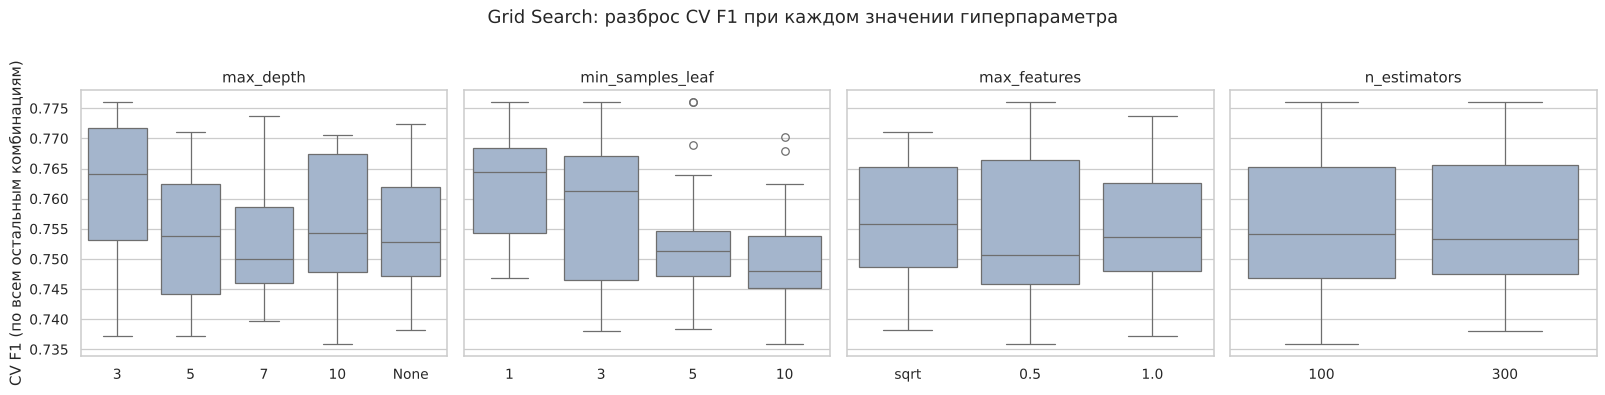

In [10]:
# Как CV F1 зависит от каждого гиперпараметра в сетке: распределение по всем остальным комбинациям
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharey=True)
for ax, p in zip(axes, PARAM_GRID):
    col = "param_" + p
    vals = grid_res[col].map(fmt)
    order = [fmt(v) for v in PARAM_GRID[p]]
    sns.boxplot(x=vals, y=grid_res["mean_test_score"], order=order, ax=ax, color="#9DB4D3")
    ax.set_title(p.replace("model__", ""))
    ax.set_xlabel("")
axes[0].set_ylabel("CV F1 (по всем остальным комбинациям)")
plt.suptitle("Grid Search: разброс CV F1 при каждом значении гиперпараметра", y=1.03)
plt.tight_layout()

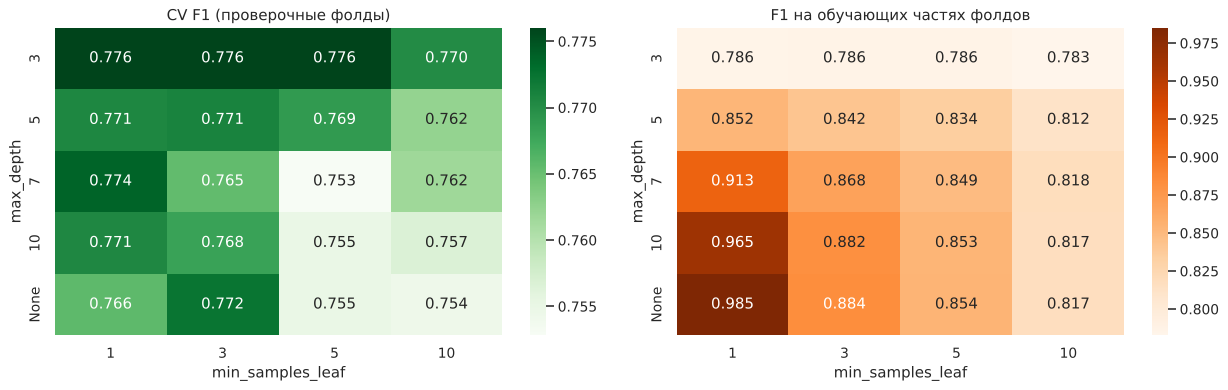

In [ ]:
# Тепловая карта: max_depth × min_samples_leaf (лучшее по остальным параметрам)     
heat = (grid_res.assign(depth=grid_res["param_model__max_depth"].map(fmt))
        .pivot_table(index="depth", columns="param_model__min_samples_leaf", values="mean_test_score", aggfunc="max"))
heat = heat.loc[[fmt(v) for v in PARAM_GRID["model__max_depth"]]]
heat_train = (grid_res.assign(depth=grid_res["param_model__max_depth"].map(fmt))
              .pivot_table(index="depth", columns="param_model__min_samples_leaf", values="mean_train_score", aggfunc="max"))
heat_train = heat_train.loc[heat.index]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="Greens", ax=axes[0])
axes[0].set_title("CV F1 (проверочные фолды)")
sns.heatmap(heat_train, annot=True, fmt=".3f", cmap="Oranges", ax=axes[1])
axes[1].set_title("F1 на обучающих частях фолдов")
for ax in axes:
    ax.set_xlabel("min_samples_leaf")
    ax.set_ylabel("max_depth")
plt.tight_layout()

**Выводы по Grid Search.**
* Проверено **120 комбинаций** (600 обучений), поиск занял **≈ 1.5–2 минуты** (точное время — в выводе выше, оно зависит от компьютера).
* **Лучший набор:** `max_depth = 3`, `max_features = 0.5`, `min_samples_leaf = 1`, `n_estimators = 100`, **CV F1 = 0.776 ± 0.042**. Это на 0.010 выше baseline (0.766).
* **Первые 6 строк таблицы имеют одинаковый результат** (0.7760 на каждом фолде). При глубине 3 у дерева не больше 8 листьев, и в каждом листе десятки пассажиров, поэтому ограничение `min_samples_leaf` ≤ 5 просто не срабатывает. А 100 и 300 деревьев одинаковой глубины 3 дают одни и те же ответы. `GridSearchCV` при равенстве берёт первую комбинацию — поэтому выбраны `min_samples_leaf = 1` и `n_estimators = 100`.
* **Boxplot по параметрам:** лучше всего в среднем `max_depth = 3`; меньший `min_samples_leaf` в среднем лучше; `max_features` влияет слабо; `n_estimators` (100 или 300) — почти никак.
* **Тепловые карты** показывают компромисс сложности. Справа F1 на обучающих частях растёт с глубиной и падает с ростом листа: от 0.786 (глубина 3) до 0.985 (без ограничений, лист 1) — модель всё лучше запоминает train. Слева CV F1 почти везде в диапазоне 0.75–0.776; максимум — в «простом» углу (глубина 3), где разрыв между train и CV всего ≈ 0.01. У глубоких деревьев с листом 1 разрыв ≈ 0.2 — это переобучение.
* Важно: разница между лучшими конфигурациями (0.770–0.776) **намного меньше разброса по фолдам** (≈ 0.04). Поверхность качества почти плоская — много разных настроек дают примерно одинаковый результат.

## 6. Random Search

Вместо сетки задаём **распределения** и случайно выбираем из них комбинации. Диапазоны те же по смыслу, но значения не ограничены несколькими точками:
* `max_depth` — целое от 2 до 20 или `None`;
* `min_samples_leaf` — целое от 1 до 20;
* `max_features` — непрерывная доля от 0.1 до 1.0;
* `n_estimators` — целое от 50 до 500.

**Бюджет:** `n_iter = 120` — ровно столько же комбинаций, сколько в сетке (120 × 5 = 600 обучений). Так сравнение честное: одинаковое число проверенных вариантов.

In [12]:
PARAM_DIST = {
    "model__max_depth": [None] + list(range(2, 21)),
    "model__min_samples_leaf": randint(1, 21),
    "model__max_features": uniform(0.1, 0.9),      # равномерно на [0.1, 1.0]
    "model__n_estimators": randint(50, 501),
}
N_ITER = n_grid  # сопоставимый вычислительный бюджет

random_search, rand_res, rand_time = run_search(RandomizedSearchCV(
    make_model(), PARAM_DIST, n_iter=N_ITER, cv=cv, scoring=SCORING, n_jobs=N_JOBS,
    random_state=RANDOM_STATE, return_train_score=True))

print(f"Время поиска: {rand_time:.1f} с")
print("Лучший набор:", short(random_search.best_params_))
print(f"Лучший CV F1: {random_search.best_score_:.4f} ± {rand_res.loc[random_search.best_index_, 'std_test_score']:.4f}")
print("\n10 лучших комбинаций Random Search:")
top_table(rand_res)

Время поиска: 141.6 с
Лучший набор: {'max_depth': None, 'max_features': 0.671, 'min_samples_leaf': 2, 'n_estimators': 102}
Лучший CV F1: 0.7766 ± 0.0254

10 лучших комбинаций Random Search:


,max_depth,min_samples_leaf,max_features,n_estimators,CV F1,CV std,train F1,"время обучения, с"
0,None,2,0.6709,102,0.7766,0.0254,0.9098,0.1495
1,4,3,0.2286,199,0.7753,0.0384,0.7780,0.3102
2,8,1,0.9412,321,0.7738,0.0146,0.9269,0.5776
3,8,1,0.7561,428,0.7736,0.0227,0.9244,0.7642
4,7,1,0.9431,316,0.7720,0.0223,0.9105,0.4875
5,10,1,0.6633,374,0.7714,0.0200,0.9522,0.6069
6,7,1,0.9161,426,0.7696,0.0196,0.9103,0.7523
7,20,1,0.8984,457,0.7689,0.0152,0.9852,0.8113
8,12,1,0.4494,466,0.7687,0.0282,0.9631,0.6553
9,12,4,0.9455,319,0.7676,0.0260,0.8655,0.5234


In [13]:
# Сколько разных значений каждого параметра реально проверил каждый метод
distinct = pd.DataFrame({
    "Grid Search": {p.replace("model__", ""): grid_res["param_" + p].map(fmt).nunique() for p in PARAM_GRID},
    "Random Search": {p.replace("model__", ""): rand_res["param_" + p].map(fmt).nunique() for p in PARAM_DIST},
})
distinct.index.name = "разных значений"
distinct

,Grid Search,Random Search
разных значений,,
max_depth,5,20
min_samples_leaf,4,20
max_features,3,120
n_estimators,2,106


In [14]:
compare_search = pd.DataFrame({
    "Grid Search": {"комбинаций": len(grid_res), "обучений": len(grid_res) * N_FOLDS,
                    "время, с": grid_time, "лучший CV F1": grid_search.best_score_,
                    "std по фолдам": grid_res.loc[grid_search.best_index_, "std_test_score"]},
    "Random Search": {"комбинаций": len(rand_res), "обучений": len(rand_res) * N_FOLDS,
                      "время, с": rand_time, "лучший CV F1": random_search.best_score_,
                      "std по фолдам": rand_res.loc[random_search.best_index_, "std_test_score"]},
}).T
compare_search

,комбинаций,обучений,"время, с",лучший CV F1,std по фолдам
Grid Search,120.0,600.0,101.5810,0.7760,0.0418
Random Search,120.0,600.0,141.6095,0.7766,0.0254


Random Search, лучший CV F1 среди первых  10 комбинаций: 0.7753
Random Search, лучший CV F1 среди первых  20 комбинаций: 0.7753
Random Search, лучший CV F1 среди первых  30 комбинаций: 0.7753
Random Search, лучший CV F1 среди первых  60 комбинаций: 0.7766
Random Search, лучший CV F1 среди первых 120 комбинаций: 0.7766


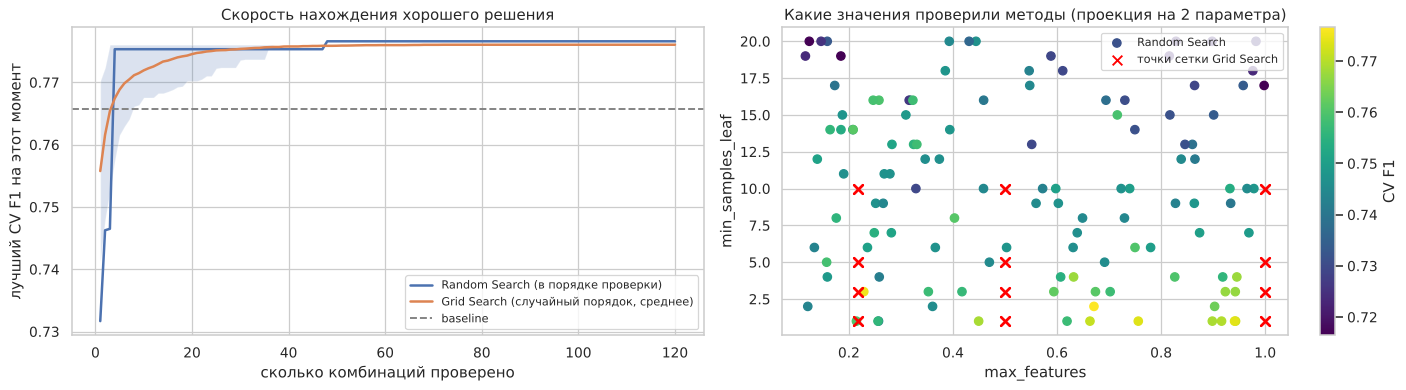

In [15]:
# Как быстро каждый метод находит хорошее решение: лучший CV F1 среди первых k проверенных комбинаций.
# Порядок сетки фиксированный (перебор по порядку), поэтому для неё усредняем по 200 случайным перестановкам.
rng = np.random.RandomState(RANDOM_STATE)
ks = np.arange(1, N_ITER + 1)
rand_curve = np.maximum.accumulate(rand_res["mean_test_score"].values)
grid_scores = grid_res["mean_test_score"].values
grid_curves = np.array([np.maximum.accumulate(rng.permutation(grid_scores)) for _ in range(200)])

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(ks, rand_curve, label="Random Search (в порядке проверки)", lw=2)
axes[0].plot(ks, grid_curves.mean(axis=0), label="Grid Search (случайный порядок, среднее)", lw=2)
axes[0].fill_between(ks, np.percentile(grid_curves, 10, axis=0), np.percentile(grid_curves, 90, axis=0), alpha=0.2)
axes[0].axhline(base_folds.mean(), color="gray", ls="--", label="baseline")
axes[0].set_xlabel("сколько комбинаций проверено")
axes[0].set_ylabel("лучший CV F1 на этот момент")
axes[0].set_title("Скорость нахождения хорошего решения")
axes[0].legend(fontsize=9)

sc = axes[1].scatter(rand_res["param_model__max_features"].astype(float),
                     rand_res["param_model__min_samples_leaf"].astype(float),
                     c=rand_res["mean_test_score"], cmap="viridis", s=45, label="Random Search")
gx = grid_res["param_model__max_features"].replace("sqrt", np.sqrt(21) / 21).astype(float)
axes[1].scatter(gx, grid_res["param_model__min_samples_leaf"].astype(float), marker="x", color="red",
                s=60, label="точки сетки Grid Search")
plt.colorbar(sc, ax=axes[1], label="CV F1")
axes[1].set_xlabel("max_features")
axes[1].set_ylabel("min_samples_leaf")
axes[1].set_title("Какие значения проверили методы (проекция на 2 параметра)")
axes[1].legend(fontsize=9, loc="upper right")
plt.tight_layout()

for k in [10, 20, 30, 60, 120]:
    print(f"Random Search, лучший CV F1 среди первых {k:>3} комбинаций: {rand_curve[k - 1]:.4f}")

**Выводы по Random Search и сравнение с Grid Search.**

| | Grid Search | Random Search |
|---|---|---|
| Комбинаций / обучений | 120 / 600 | 120 / 600 |
| Время | ≈ 1.5–2 мин | ≈ 2–2.5 мин |
| Лучший CV F1 | 0.7760 ± 0.042 | 0.7766 ± 0.025 |
| Лучшие параметры | глубина 3, лист 1, max_features 0.5, 100 деревьев | глубина None, лист 2, max_features 0.67, 102 дерева |

* **По качеству** методы практически равны: разница 0.0006 — это шум. Но нашли они **разные области**: Grid — неглубокие деревья, Random — глубокие деревья с листом ≥ 2 и большей долей признаков. Это ещё раз показывает, что поверхность качества плоская: «простая модель» и «сложная модель с регуляризацией листом» дают одинаковый CV.
* **По времени** Random Search в 1.3–1.5 раза дольше, хотя комбинаций столько же. Точные секунды меняются от запуска к запуску и зависят от компьютера — они в таблице выше. Причина — `n_estimators` выбирался из 50–500 (в среднем ≈ 275 деревьев), а в сетке было 100 или 300 (в среднем 200). Время определяется не числом комбинаций, а суммарной стоимостью обучений.
* **По покрытию** Random Search проверил 20 разных значений глубины, 20 — размера листа, 120 — `max_features` и 106 — числа деревьев. Сетка — только 5, 4, 3 и 2. При том же бюджете случайный поиск исследует каждую ось гораздо подробнее (график справа: красные крестики сетки стоят в нескольких точках, синие точки случайного поиска покрывают всю область).
* **По скорости** Random Search уже среди **первых 10 комбинаций** нашёл CV F1 = 0.775 — почти итоговый результат. Остальные 110 улучшили его лишь на 0.001.
* Половина бюджета сетки ушла на `n_estimators = 300`, которое дало те же результаты, что 100. Это типичная слабость Grid Search: если параметр неважен, сетка всё равно перебирает его значения для каждой комбинации остальных.

**Когда Random Search предпочтительнее полного перебора:**
* параметров много, и заранее неизвестно, какие из них важны — сетка тратит бюджет на повторение неважных значений;
* есть непрерывные параметры (`max_features`, `learning_rate`, `C`) — сетка проверяет лишь несколько точек, а случайный поиск — много разных значений;
* бюджет ограничен: число проверок задаётся явно (`n_iter`) и не растёт как произведение размеров сетки;
* пространство большое, и важно быстро найти «хорошую область», а потом, при желании, уточнить её сеткой.

**Grid Search уместнее**, когда параметров 1–2, значений немного и нужно гарантированно проверить все варианты (полная воспроизводимость, понятно, что проверено). Минус случайного поиска — результат зависит от `random_state` и `n_iter`.

## 7. Влияние отдельных гиперпараметров

Строим **validation curves**: меняем один гиперпараметр, остальные фиксируем на лучших значениях Grid Search, и для каждого значения считаем F1 на обучающих частях фолдов (train) и на проверочных (CV). Всё — только на train-выборке.

In [16]:
BEST_GRID = strip_prefix(grid_search.best_params_)
CURVES = {
    "max_depth": [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 15, 20, None],
    "min_samples_leaf": [1, 2, 3, 5, 8, 12, 20, 30, 50, 80],
    "max_features": [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0],
    "n_estimators": [1, 3, 5, 10, 25, 50, 100, 200, 400],
}


def curve(param, values, base_params):
    """Validation curve для одного гиперпараметра; остальные — из base_params."""
    fixed = {k: v for k, v in base_params.items() if k != param}
    tr, va = validation_curve(make_model(**fixed), X_train, y_train, param_name=f"model__{param}",
                              param_range=values, cv=cv, scoring=SCORING, n_jobs=N_JOBS)
    labels = ["None" if v is None else v for v in values]
    return pd.DataFrame({"значение": labels, "train F1": tr.mean(1), "CV F1": va.mean(1), "CV std": va.std(1)})


curves = {p: curve(p, v, BEST_GRID) for p, v in CURVES.items()}
# тот же min_samples_leaf, но для деревьев без ограничения глубины — там листья — единственный ограничитель сложности
curves["min_samples_leaf (max_depth=None)"] = curve("min_samples_leaf", CURVES["min_samples_leaf"],
                                                    {**BEST_GRID, "max_depth": None})
print("Фиксированные значения остальных параметров:", BEST_GRID)

Фиксированные значения остальных параметров: {'max_depth': 3, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 100}


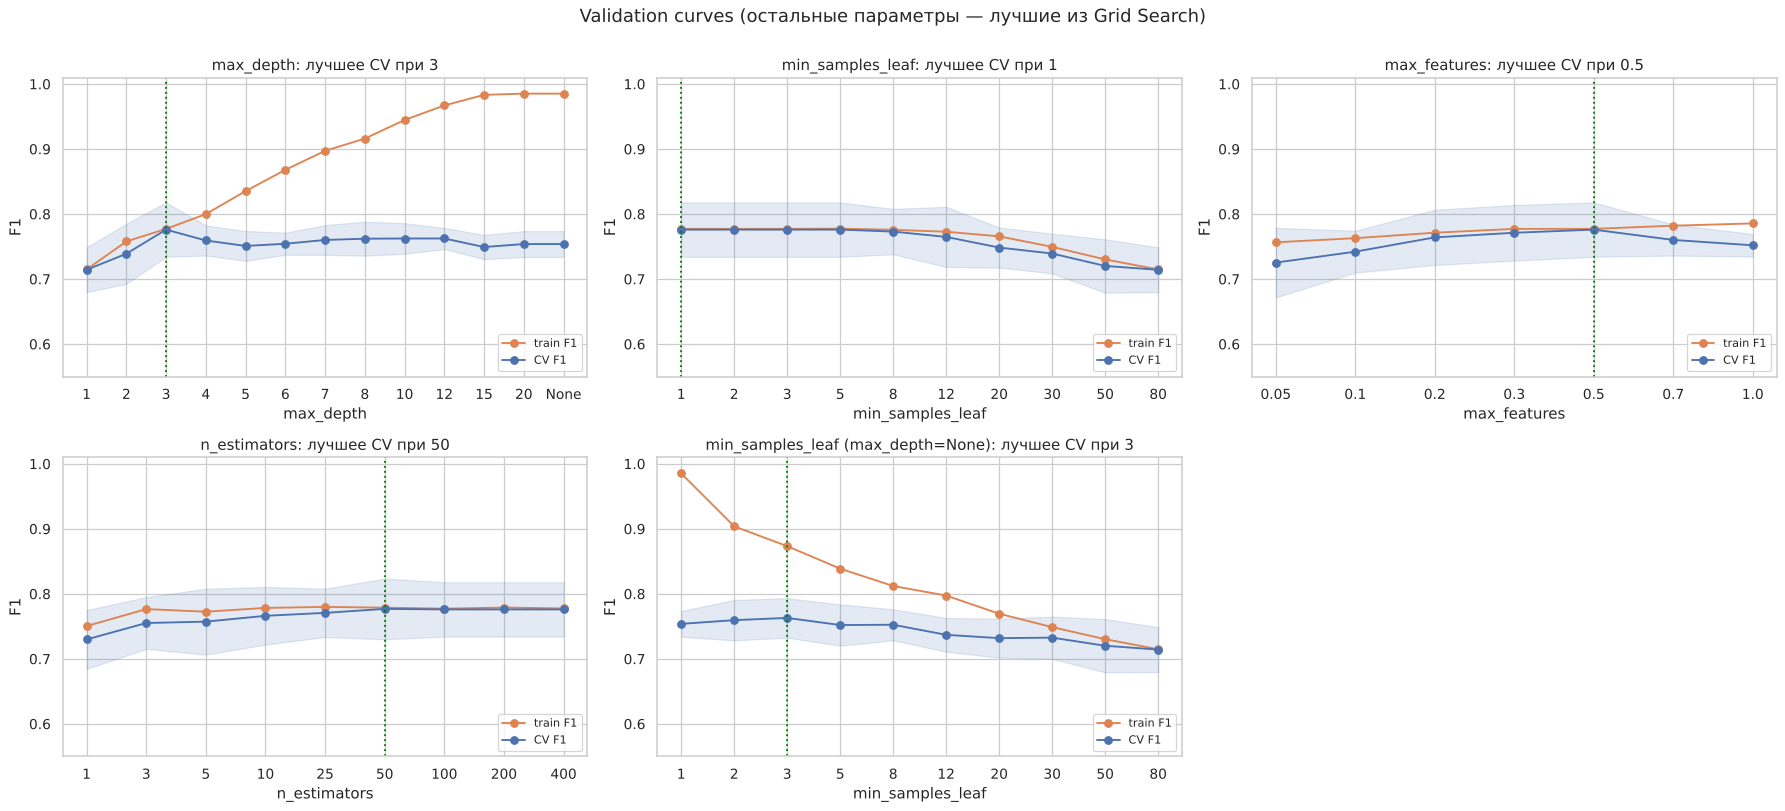

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(20, 9))
axes.ravel()[-1].axis("off")
for ax, (p, c) in zip(axes.ravel(), curves.items()):
    x = np.arange(len(c))
    ax.plot(x, c["train F1"], "o-", label="train F1", color="#DD8452")
    ax.plot(x, c["CV F1"], "o-", label="CV F1", color="#4C72B0")
    ax.fill_between(x, c["CV F1"] - c["CV std"], c["CV F1"] + c["CV std"], alpha=0.15, color="#4C72B0")
    best = int(c["CV F1"].idxmax())
    ax.axvline(best, color="green", ls=":", lw=1.5)
    ax.set_xticks(x)
    ax.set_xticklabels(c["значение"].astype(str))
    ax.set_title(f"{p}: лучшее CV при {c['значение'][best]}")
    ax.set_xlabel(p.split(" ")[0])
    ax.set_ylabel("F1")
    ax.legend(loc="lower right", fontsize=9)
    ax.set_ylim(0.55, 1.01)
plt.suptitle("Validation curves (остальные параметры — лучшие из Grid Search)", y=1.0)
plt.tight_layout()

In [18]:
for p, c in curves.items():
    print(f"\n{p}:")
    print(c.round(3).to_string(index=False))


max_depth:
значение  train F1  CV F1  CV std
       1     0.715  0.714   0.035
       2     0.758  0.739   0.046
       3     0.777  0.776   0.042
       4     0.800  0.759   0.023
       5     0.835  0.751   0.023
       6     0.868  0.754   0.017
       7     0.897  0.760   0.023
       8     0.916  0.762   0.026
      10     0.945  0.762   0.024
      12     0.967  0.762   0.016
      15     0.983  0.749   0.019
      20     0.985  0.754   0.020
    None     0.985  0.754   0.020

min_samples_leaf:
 значение  train F1  CV F1  CV std
        1     0.777  0.776   0.042
        2     0.777  0.776   0.042
        3     0.777  0.776   0.042
        5     0.778  0.776   0.042
        8     0.776  0.773   0.035
       12     0.773  0.765   0.046
       20     0.766  0.748   0.031
       30     0.750  0.739   0.031
       50     0.730  0.720   0.041
       80     0.715  0.714   0.035

max_features:
 значение  train F1  CV F1  CV std
     0.05     0.757  0.725   0.054
     0.10     0.763  0.

**Выводы о влиянии гиперпараметров.**

**`max_depth`** — самый наглядный параметр, на нём видны все три области:
* **недообучение — глубина 1–2:** F1 низкий и на train (0.72–0.76), и на CV (0.71–0.74). Деревья успевают задать 1–2 вопроса (по сути, только пол), этого мало;
* **разумная сложность — глубина 3–4:** CV максимален (0.776 при глубине 3), разрыв train / CV минимальный (≈ 0.00–0.04);
* **переобучение — глубина ≥ 6:** F1 на train растёт до 0.985, а CV остаётся на уровне 0.75–0.76. Разрыв 0.1–0.23 — деревья запоминают отдельных пассажиров. CV не падает резко потому, что лес усредняет много переобученных деревьев, и их ошибки частично гасятся.

**`min_samples_leaf`** (при `max_depth = 3`): значения 1–8 дают одинаковый результат — глубина 3 и так ограничивает дерево. При ≥ 12 обе кривые снижаются вместе — **недообучение**: листья слишком крупные, мелкие группы (мальчики, большие семьи) теряются. При 80 качество такое же, как у дерева глубины 1.

**`min_samples_leaf` при `max_depth = None`** — здесь видны все области: лист 1 — **переобучение** (train 0.985, CV 0.754); лист 2–3 — **оптимум** (CV 0.760–0.763, разрыв меньше); лист ≥ 20 — **недообучение** (обе кривые падают). То есть размер листа работает как регуляризация глубоких деревьев: тот же эффект, что ограничение глубины, другим способом.

**`max_features`:** при 0.05–0.1 в каждом разбиении выбор идёт из 1–2 случайных признаков, часто бесполезных (порт, `Parch`), — деревья слабые, CV 0.725–0.742 (**недообучение**). Оптимум — 0.3–0.5. При 1.0 все деревья видят все признаки и становятся почти одинаковыми (все начинают с `Title_Mr`), лес теряет выгоду от разнообразия: train растёт, CV падает до 0.752 — ближе к одному переобученному дереву.

**`n_estimators`:** одно дерево — 0.73, дальше CV растёт до ≈ 50 деревьев (0.777) и выходит на плато. **Переобучения от числа деревьев нет**: больше деревьев только уменьшают случайность усреднения. После 50–100 деревьев добавлять их бессмысленно — время растёт, качество нет.

**Итог:** сильнее всего на качество влияют параметры сложности отдельного дерева (`max_depth`, `min_samples_leaf`), умеренно — `max_features`, слабее всего — `n_estimators`. Предположения из раздела 4 подтвердились, кроме оптимальной глубины: она оказалась меньше ожидаемой (3, а не 4–8) — сигнал в данных простой (пол + класс + семья), и для него хватает трёх вопросов.

## 8. Финальная модель и оценка на test

Сравниваем три кандидата:
1. исходную модель (baseline, параметры по умолчанию);
2. лучшую модель Grid Search;
3. лучшую модель Random Search.

### 8.1. Выбор итоговой модели — только по train

Лучшие CV F1 Grid Search (0.776) и Random Search (0.777) отличаются на 0.0006 — это меньше любой разумной погрешности. Кроме того, `best_score_` **оптимистичен**: мы выбрали максимум из 120 вариантов, и часть его «успеха» — удачное совпадение с конкретными 5 фолдами (эффект «проклятия победителя»). Поэтому перед тестом **перепроверим трёх кандидатов на новых разбиениях train** — повторённой кросс-валидацией 5 фолдов × 10 повторов (50 оценок). Это по-прежнему только обучающая выборка, тест в выборе не участвует.

In [19]:
candidates = {
    "Исходная модель (baseline)": BASELINE_PARAMS,
    "Grid Search": strip_prefix(grid_search.best_params_),
    "Random Search": strip_prefix(random_search.best_params_),
}
search_folds = {
    "Исходная модель (baseline)": base_folds,
    "Grid Search": np.array([grid_res.loc[grid_search.best_index_, f"split{i}_test_score"] for i in range(N_FOLDS)]),
    "Random Search": np.array([rand_res.loc[random_search.best_index_, f"split{i}_test_score"] for i in range(N_FOLDS)]),
}
recheck = {name: cv_report(make_model(**params), splitter=cv_check)[0] for name, params in candidates.items()}
selection = pd.DataFrame({
    name: {"гиперпараметры": short(candidates[name]),
           "CV F1 (5 фолдов, поиск)": search_folds[name].mean(),
           "CV F1 (5×10, новые разбиения)": recheck[name].mean(),
           "std (50 оценок)": recheck[name].std(),
           "прирост к baseline (5×10)": recheck[name].mean() - recheck["Исходная модель (baseline)"].mean()}
    for name in candidates}).T
CHOSEN = selection["CV F1 (5×10, новые разбиения)"].astype(float).idxmax()
print("Итоговая модель (лучшая по повторённой CV на train):", CHOSEN)
selection

Итоговая модель (лучшая по повторённой CV на train): Grid Search


,гиперпараметры,"CV F1 (5 фолдов, поиск)","CV F1 (5×10, новые разбиения)",std (50 оценок),прирост к baseline (5×10)
Исходная модель (baseline),"{'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt'}",0.7656,0.7573,0.0447,0.0
Grid Search,"{'max_depth': 3, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 100}",0.776,0.7719,0.0438,0.0147
Random Search,"{'max_depth': None, 'max_features': 0.671, 'min_samples_leaf': 2, 'n_estimators': 102}",0.7766,0.764,0.0449,0.0067


### 8.2. Оценка на test

Решение принято. Теперь обучаем три модели на **всём train** с выбранными параметрами и **один раз** оцениваем на тестовой выборке. (`GridSearchCV` и `RandomizedSearchCV` с `refit=True` уже переобучили свои лучшие модели на всём train — это `best_estimator_`.)

In [20]:
fitted_final = {
    "Исходная модель (baseline)": make_model(**BASELINE_PARAMS).fit(X_train, y_train),
    "Grid Search": grid_search.best_estimator_,
    "Random Search": random_search.best_estimator_,
}
final_table = pd.DataFrame({
    name: {"CV F1 (5 фолдов)": search_folds[name].mean(), "CV F1 (5×10)": recheck[name].mean(),
           **test_report(model)}
    for name, model in fitted_final.items()}).T
final_table["итоговая"] = np.where(final_table.index == CHOSEN, "✓", "")
final_table

,CV F1 (5 фолдов),CV F1 (5×10),Test F1,Test Accuracy,Test Precision,Test Recall,итоговая
Исходная модель (baseline),0.7656,0.7573,0.7482,0.8045,0.7429,0.7536,
Grid Search,0.7760,0.7719,0.7132,0.7933,0.7667,0.6667,✓
Random Search,0.7766,0.7640,0.7176,0.7933,0.7581,0.6812,


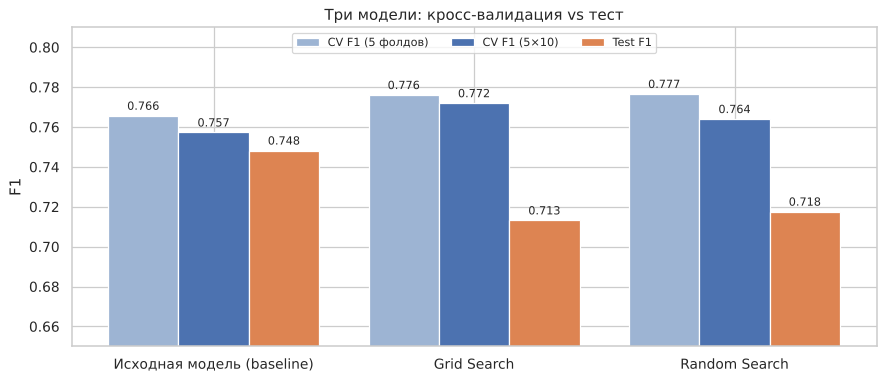

In [21]:
fig, ax = plt.subplots(figsize=(10, 4.4))
xx = np.arange(len(final_table))
w = 0.27
for k, (col, color) in enumerate([("CV F1 (5 фолдов)", "#9DB4D3"), ("CV F1 (5×10)", "#4C72B0"), ("Test F1", "#DD8452")]):
    vals = final_table[col].astype(float)
    ax.bar(xx + (k - 1) * w, vals, w, label=col, color=color)
    for i, v in enumerate(vals):
        ax.text(i + (k - 1) * w, v + 0.003, f"{v:.3f}", ha="center", fontsize=9)
ax.set_xticks(xx)
ax.set_xticklabels(final_table.index)
ax.set_ylim(0.65, 0.81)
ax.set_ylabel("F1")
ax.set_title("Три модели: кросс-валидация vs тест")
ax.legend(loc="upper center", ncol=3, fontsize=9)
plt.tight_layout()

### 8.3. Почему улучшение на CV может не перейти на test

Оценим, насколько «шумит» тест из 179 пассажиров: возьмём 1000 bootstrap-подвыборок теста (случайный выбор пассажиров с возвращением) и посмотрим разброс F1. Это анализ уже полученного результата — на выбор модели он не влияет.

In [22]:
rng = np.random.RandomState(RANDOM_STATE)
preds = {name: m.predict(X_test) for name, m in fitted_final.items()}
boot = []
for _ in range(1000):
    idx = rng.randint(0, len(y_test), len(y_test))
    boot.append({name: f1_score(y_test.values[idx], p[idx]) for name, p in preds.items()})
boot = pd.DataFrame(boot)
print("Разброс Test F1 на bootstrap-подвыборках теста (95% интервал):")
print(boot.quantile([0.025, 0.5, 0.975]).T.round(3).rename(columns={0.025: "2.5%", 0.5: "медиана", 0.975: "97.5%"}))
diff = boot[CHOSEN] - boot["Исходная модель (baseline)"]
print(f"\nРазница {CHOSEN} − baseline на тесте: медиана {diff.median():+.3f}, 95% интервал [{diff.quantile(0.025):+.3f}, {diff.quantile(0.975):+.3f}]")
n_diff = (preds[CHOSEN] != preds["Исходная модель (baseline)"]).sum()
print(f"Пассажиров, по которым {CHOSEN} и baseline отвечают по-разному: {n_diff} из {len(y_test)}")
both = pd.crosstab(pd.Series(preds["Исходная модель (baseline)"] == y_test.values, name="baseline прав"),
                   pd.Series(preds[CHOSEN] == y_test.values, name=f"{CHOSEN} прав"))
both

Разброс Test F1 на bootstrap-подвыборках теста (95% интервал):
                             2.5%  медиана  97.5%
Исходная модель (baseline)  0.667    0.750  0.821
Grid Search                 0.619    0.714  0.791
Random Search               0.622    0.719  0.797

Разница Grid Search − baseline на тесте: медиана -0.037, 95% интервал [-0.112, +0.043]
Пассажиров, по которым Grid Search и baseline отвечают по-разному: 24 из 179


Grid Search прав,False,True
baseline прав,,
False,24,11
True,13,131


**Итоговое сравнение трёх моделей.**

| Модель | Гиперпараметры | CV F1 (5 фолдов) | CV F1 (5×10) | Test F1 |
|---|---|---|---|---|
| Исходная (baseline) | 100 деревьев, глубина None, лист 1, `sqrt` | 0.766 | 0.757 | **0.748** |
| **Grid Search** (итоговая) | 100 деревьев, глубина 3, лист 1, 0.5 | 0.776 | **0.772** | 0.713 |
| Random Search | 102 дерева, глубина None, лист 2, 0.67 | **0.777** | 0.764 | 0.718 |

**Выбор итоговой модели.** На 5 фолдах Grid и Random Search равны, но на 50 новых разбиениях лучший набор Random Search просел сильнее (0.777 → 0.764), чем Grid Search (0.776 → 0.772). Это «проклятие победителя»: из 120 вариантов поиск выбирает тот, которому чуть повезло с конкретными 5 фолдами, и его оценка завышена. Итоговая модель — **Grid Search**, выбрана **только по train**.

**Насколько оптимизация улучшила качество.** На кросс-валидации — немного: +0.010 на 5 фолдах и +0.015 на повторённой CV. Random Forest по умолчанию уже неплох (усреднение 100 деревьев гасит переобучение), а данные маленькие и с простым сигналом, так что большого запаса для улучшения нет.

**Совпадает ли улучшение на CV с результатом на test? Нет.** На тесте оптимизированные модели **хуже** baseline: 0.713 и 0.718 против 0.748.

**Чем это объясняется:**
1. **Тест маленький.** В нём 69 выживших. Bootstrap показывает, что 95% интервал Test F1 у каждой модели — примерно ±0.08 (например, у Grid Search 0.62–0.79). Интервал разницы «Grid − baseline» — от −0.11 до +0.04, то есть **включает ноль**: по этому тесту нельзя утверждать, что какая-то модель лучше.
2. **Модели расходятся всего на 24 пассажирах из 179.** На 13 из них прав baseline, на 11 — Grid Search. Разница в 2 пассажира — и есть весь «проигрыш» на тесте.
3. **Само улучшение на CV (0.01–0.015) меньше разброса по фолдам (≈ 0.04).** Это реальный, но слабый эффект, который на одной выборке из 179 человек легко перекрывается случайностью.
4. **Разный характер ошибок.** Неглубокий лес (глубина 3) работает правилами по крупным группам («женщины выжили, мужчины погибли»): Precision выше (0.767 против 0.743), Recall ниже (0.667 против 0.754) — он пропускает «нетипичных» выживших. В этом тесте таких оказалось чуть больше, и глубокий baseline случайно поймал часть из них.

**Чего мы делать не будем:** менять выбор модели после того, как увидели тест. Если бы мы сейчас взяли baseline «потому что на тесте он лучше», это и был бы выбор гиперпараметров по test — критическая ошибка из задания. Наиболее надёжная оценка ожидаемого качества на новых данных — повторённая CV (≈ 0.76–0.77), а не одно число на 179 пассажирах.

## 9. Анализ устойчивости

Смотрим не только на среднее, но и на F1 **на каждом фолде** — для трёх итоговых моделей и для пар конфигураций из Grid Search с почти одинаковым средним.

In [23]:
folds_table = pd.DataFrame(search_folds,
                           index=[f"фолд {i + 1}" for i in range(N_FOLDS)]).T
folds_table["среднее"] = folds_table.mean(axis=1)
folds_table["std"] = folds_table.iloc[:, :N_FOLDS].std(axis=1, ddof=0)
folds_table["min"] = folds_table.iloc[:, :N_FOLDS].min(axis=1)
folds_table["max"] = folds_table.iloc[:, :N_FOLDS].max(axis=1)
folds_table

,фолд 1,фолд 2,фолд 3,фолд 4,фолд 5,среднее,std,min,max
Исходная модель (baseline),0.7925,0.7339,0.7850,0.7810,0.7358,0.7656,0.0254,0.7339,0.7925
Grid Search,0.7890,0.7255,0.8462,0.7429,0.7767,0.7760,0.0418,0.7255,0.8462
Random Search,0.7925,0.7321,0.8081,0.7736,0.7767,0.7766,0.0254,0.7321,0.8081


In [24]:
# Пары конфигураций Grid Search с почти одинаковым средним CV F1, но разным разбросом по фолдам
split_cols = [f"split{i}_test_score" for i in range(N_FOLDS)]
g = grid_res.sort_values("mean_test_score", ascending=False).reset_index(drop=True)
pairs = []
for i in range(len(g)):
    for j in range(i + 1, len(g)):
        if abs(g.loc[i, "mean_test_score"] - g.loc[j, "mean_test_score"]) < 0.002:
            pairs.append((i, j, abs(g.loc[i, "std_test_score"] - g.loc[j, "std_test_score"])))
i_best, j_best, _ = max(pairs, key=lambda t: t[2])
pair = g.loc[[i_best, j_best]]
pair_view = pd.DataFrame({
    "конфигурация": [str(short({k: pair.loc[r, "param_" + k] for k in PARAM_GRID})) for r in pair.index],
    **{f"фолд {k + 1}": pair[split_cols[k]].values for k in range(N_FOLDS)},
    "среднее": pair["mean_test_score"].values, "std": pair["std_test_score"].values,
}, index=["A (устойчивее)" if pair.loc[i_best, "std_test_score"] < pair.loc[j_best, "std_test_score"] else "A",
          "B"])
pair_view = pair_view.sort_values("std")
pair_view.index = ["A — устойчивая", "B — неустойчивая"]
pair_view

,конфигурация,фолд 1,фолд 2,фолд 3,фолд 4,фолд 5,среднее,std
A — устойчивая,"{'max_depth': None, 'min_samples_leaf': 1, 'max_features': 1.0, 'n_estimators': 100}",0.789,0.7523,0.7736,0.7706,0.7429,0.7657,0.0163
B — неустойчивая,"{'max_depth': 3, 'min_samples_leaf': 3, 'max_features': 'sqrt', 'n_estimators': 300}",0.789,0.6931,0.8462,0.7184,0.7843,0.7662,0.0545


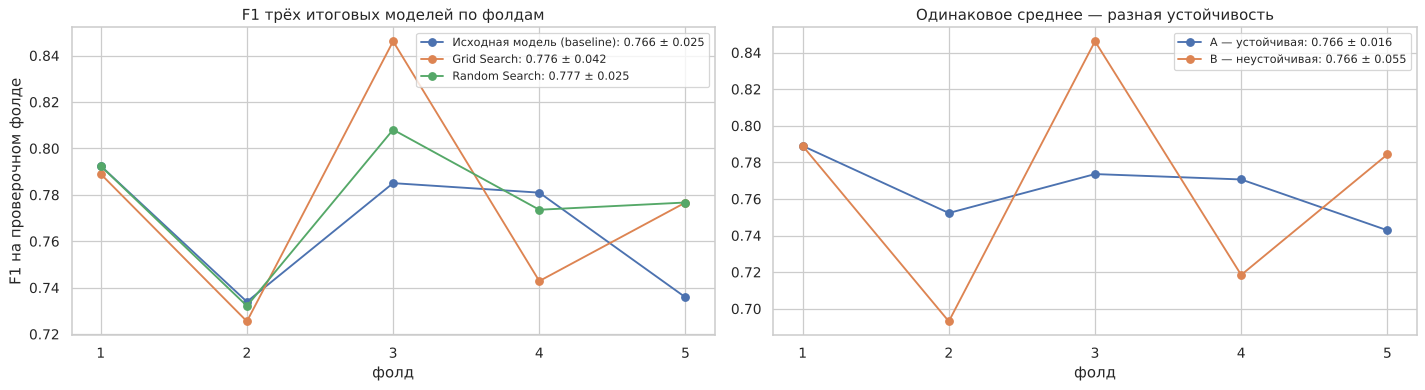

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for name, folds in search_folds.items():
    axes[0].plot(range(1, N_FOLDS + 1), folds, "o-", label=f"{name}: {folds.mean():.3f} ± {folds.std():.3f}")
axes[0].set_xticks(range(1, N_FOLDS + 1))
axes[0].set_xlabel("фолд")
axes[0].set_ylabel("F1 на проверочном фолде")
axes[0].set_title("F1 трёх итоговых моделей по фолдам")
axes[0].legend(fontsize=9)

for label, row in pair_view.iterrows():
    vals = row[[f"фолд {k + 1}" for k in range(N_FOLDS)]].values.astype(float)
    axes[1].plot(range(1, N_FOLDS + 1), vals, "o-", label=f"{label}: {row['среднее']:.3f} ± {row['std']:.3f}")
axes[1].set_xticks(range(1, N_FOLDS + 1))
axes[1].set_xlabel("фолд")
axes[1].set_title("Одинаковое среднее — разная устойчивость")
axes[1].legend(fontsize=9)
plt.tight_layout()

Корреляция max_depth (None=30) и std по фолдам: -0.224


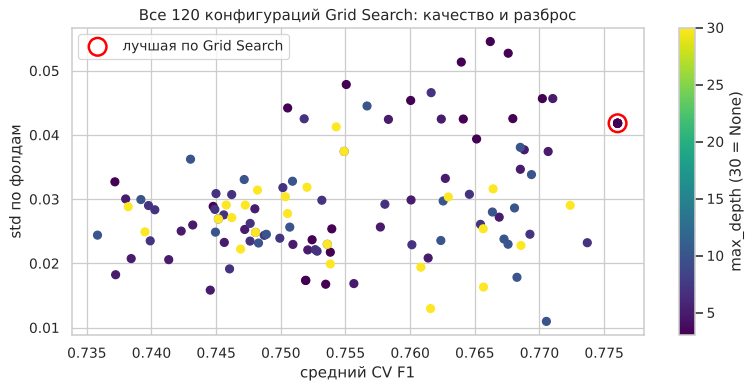

In [26]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sc = ax.scatter(grid_res["mean_test_score"], grid_res["std_test_score"],
                c=grid_res["param_model__max_depth"].map(lambda v: 30 if fmt(v) == "None" else float(v)), cmap="viridis", s=40)
plt.colorbar(sc, ax=ax, label="max_depth (30 = None)")
ax.scatter(grid_search.best_score_, grid_res.loc[grid_search.best_index_, "std_test_score"], s=200,
           facecolors="none", edgecolors="red", lw=2, label="лучшая по Grid Search")
ax.set_xlabel("средний CV F1")
ax.set_ylabel("std по фолдам")
ax.set_title("Все 120 конфигураций Grid Search: качество и разброс")
ax.legend()
plt.tight_layout()
print("Корреляция max_depth (None=30) и std по фолдам:",
      round(np.corrcoef(grid_res["param_model__max_depth"].map(lambda v: 30 if fmt(v) == "None" else float(v)), grid_res["std_test_score"])[0, 1], 3))

**Выводы по устойчивости.**
* **У всех трёх моделей фолды «трудные» и «лёгкие» одинаковые:** фолд 2 — худший (≈ 0.73), фолд 3 — лучший. Значит, большая часть разброса связана не с моделью, а с тем, какие пассажиры попали в фолд (сколько среди них «исключений» — выживших мужчин, погибших женщин).
* Разброс по 5 фолдам: baseline и Random Search — ± 0.025, Grid Search — ± 0.042 (от 0.726 до 0.846). При почти одинаковом среднем лучшая модель Grid Search **менее стабильна** на этих фолдах.
* **Пара A / B из сетки:** среднее одинаковое (0.766), но у **A** (деревья без ограничения глубины) F1 по фолдам 0.74–0.79, std 0.016, а у **B** (глубина 3) — от 0.69 до 0.85, std 0.055. Если бы мы оценивали B по одному разбиению, могли бы получить и 0.69, и 0.85 — и сделать совершенно разные выводы.

**Почему две модели с одинаковым средним различаются по устойчивости.** Среднее говорит, насколько модель хороша «в среднем по фолдам», а разброс — насколько её результат зависит от конкретных данных.
* Неглубокий лес принимает решения **крупными группами**: например, всем женщинам 3-го класса с небольшой семьёй — «выжила». Если в фолд попало много исключений из этой группы, модель ошибается на всех сразу, если мало — получает очень высокий F1. Отсюда большие качели между фолдами.
* Глубокий лес решает более «индивидуально», его ошибки распределяются равномернее, и F1 меньше зависит от состава фолда. На графике всех 120 конфигураций это видно как слабая связь: чем меньше глубина, тем в среднем больше разброс (корреляция −0.22).
* Кроме того, F1 на фолде считается всего по ≈ 55 выжившим, поэтому даже 2–3 пассажира заметно сдвигают оценку.

**Что из этого следует.** При равном среднем стоит предпочесть более устойчивую модель: её качество на новых данных предсказуемее. Но и сама оценка std по 5 фолдам шумная: на 50 разбиениях (раздел 8.1) разброс у трёх итоговых моделей практически одинаков (0.044–0.045). Поэтому выводы об устойчивости, как и о качестве, надёжнее делать по повторённой кросс-валидации.

## Итоги

* **Задача и модель:** Titanic (ЛР2), Random Forest, метрика F1. Baseline — лес с параметрами по умолчанию: CV F1 = 0.766.
* **Гиперпараметры:** `max_depth`, `min_samples_leaf`, `max_features`, `n_estimators`. Подбор — `StratifiedKFold` на 5 фолдов только по train; тест не участвовал в выборе.
* **Grid Search:** 120 комбинаций, ≈ 1.5–2 мин, лучший CV F1 0.776 (глубина 3, `max_features` 0.5). **Random Search:** те же 120 комбинаций, в 1.3–1.5 раза дольше, CV F1 0.777 (глубокие деревья, лист 2, `max_features` 0.67). Качество одинаковое, но случайный поиск гораздо подробнее покрыл каждый параметр и нашёл хорошее решение уже за 10 попыток.
* **Влияние параметров:** `max_depth` и `min_samples_leaf` управляют сложностью — видны недообучение (глубина 1–2, крупные листья), оптимум (глубина 3–4) и переобучение (глубина ≥ 6, лист 1). `max_features` важен умеренно, `n_estimators` после ≈ 50 деревьев почти не влияет.
* **Финал:** выбран Grid Search (лучший на повторённой CV 0.772 против 0.757 у baseline). На тесте он получил 0.713 против 0.748 у baseline — улучшение на CV не подтвердилось. Это объясняется малым тестом (интервал разницы включает 0, модели расходятся на 24 пассажирах) и малой величиной самого улучшения. Решение не пересматривалось по тесту.
* **Главный вывод:** на маленьком датасете с простым сигналом оптимизация гиперпараметров даёт небольшой выигрыш, а честная оценка требует смотреть на разброс — по фолдам, по повторениям CV и по тесту — а не на одно число.